# Logistic Regression on the Breast Cancer Dataset

This notebook walks through the same idea as `bcancer.py` — training a `LogisticRegression` model on the scikit-learn **Wisconsin breast cancer** dataset — but step by step, with extra exploration and plots so we can actually *see* what the model is doing.

We'll cover:
1. Loading and looking at the data
2. Splitting into train/test sets
3. Training the (full, 30-feature) logistic regression model
4. Evaluating it with a **confusion matrix** and **ROC curve**
5. Visualizing the logistic **sigmoid (S-curve)** using a single predictor, since we can't easily plot a 30-dimensional sigmoid

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
)

sns.set_theme(style="whitegrid")

## 1. Load and explore the data

`load_breast_cancer()` returns 30 numeric features computed from digitized images of breast masses (things like `mean radius`, `mean texture`, `worst area`, etc.) and a binary `target`:
- `0` = malignant
- `1` = benign

Let's load it into a pandas DataFrame so it's easy to inspect.

In [2]:
data = load_breast_cancer()
# print(data)
# print(data.feature_names)

df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target
df["diagnosis"] = df["target"].map({0: "malignant", 1: "benign"})

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,malignant


In [3]:
print(f"Shape: {df.shape[0]} samples x {df.shape[1]} columns")
df.describe()

Shape: 569 samples x 32 columns


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


How balanced are the two classes? Logistic regression (and accuracy as a metric) work best when we understand this up front.

diagnosis
benign       357
malignant    212
Name: count, dtype: int64


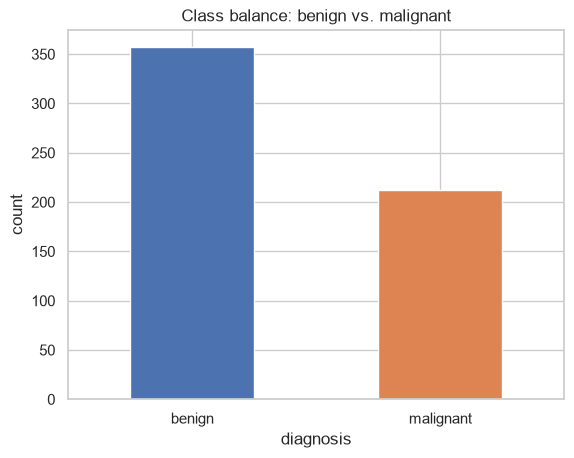

In [4]:
counts = df["diagnosis"].value_counts()
print(counts)

counts.plot(kind="bar", color=["#4C72B0", "#DD8452"])
plt.title("Class balance: benign vs. malignant")
plt.ylabel("count")
plt.xticks(rotation=0)
plt.show()

## 2. Train/test split

We hold out 20% of the data as a test set so we can measure how well the model generalizes to samples it never saw during training, exactly like `bcancer.py`.

In [5]:
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Train: {X_train.shape[0]} samples, Test: {X_test.shape[0]} samples")

Train: 455 samples, Test: 114 samples


## 3. Train the full logistic regression model

This uses all 30 features, same as `bcancer.py`. `max_iter=5000` just gives the solver enough iterations to converge.

In [6]:
model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]  # predicted probability of class 1 (benign)

print("Accuracy:", accuracy_score(y_test, y_pred))
print()
print(classification_report(y_test, y_pred, target_names=["malignant", "benign"]))

Accuracy: 0.956140350877193

              precision    recall  f1-score   support

   malignant       0.97      0.91      0.94        43
      benign       0.95      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



## 4. Confusion matrix

The confusion matrix breaks accuracy down into **true positives / negatives** and **false positives / negatives**, which is important in a medical context where the two mistake types (missing a malignant tumor vs. a false alarm) have very different costs.

- Rows = actual class, Columns = predicted class

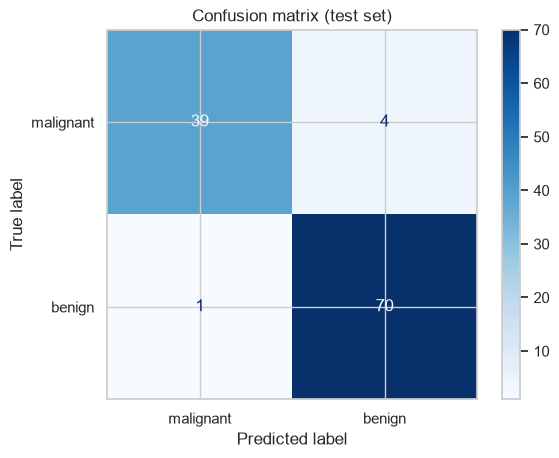

In [7]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["malignant", "benign"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix (test set)")
plt.show()

## 5. ROC curve and AUC

The ROC curve plots the **true positive rate** against the **false positive rate** as we sweep the classification threshold from 0 to 1 (instead of fixing it at 0.5). The **AUC** (area under the curve) summarizes this in a single number: 1.0 is a perfect classifier, 0.5 is random guessing.

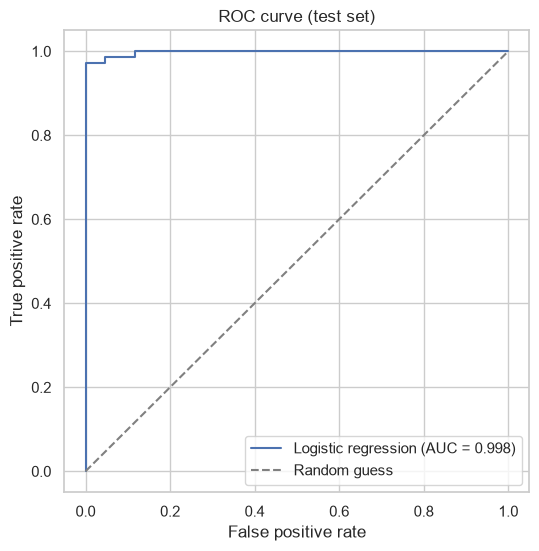

In [8]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"Logistic regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve (test set)")
plt.legend()
plt.show()

## 6. Visualizing the sigmoid (S-curve)

Logistic regression works by fitting a linear combination of features, then squashing it through the **sigmoid function**:

$$ P(y=1 \mid x) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_{30} x_{30})}} $$

With 30 features, that S-curve lives in 30-dimensional space and can't be drawn directly. To actually *see* the sigmoid shape, we'll fit a **separate, simpler model** using just a single predictor — `mean radius` — which tends to be strongly associated with malignancy. This lets us plot probability vs. feature value as a genuine 2D S-curve.

In [9]:
feature_name = "mean radius"
feature_idx = list(data.feature_names).index(feature_name)

x_single = X[:, feature_idx].reshape(-1, 1)

x_train_single, x_test_single, y_train_single, y_test_single = train_test_split(
    x_single, y, test_size=0.2, random_state=42
)

single_model = LogisticRegression()
single_model.fit(x_train_single, y_train_single)

single_acc = accuracy_score(y_test_single, single_model.predict(x_test_single))
print(f"Accuracy using only '{feature_name}': {single_acc:.3f}")
print(f"(Full 30-feature model accuracy was: {accuracy_score(y_test, y_pred):.3f})")

Accuracy using only 'mean radius': 0.912
(Full 30-feature model accuracy was: 0.956)


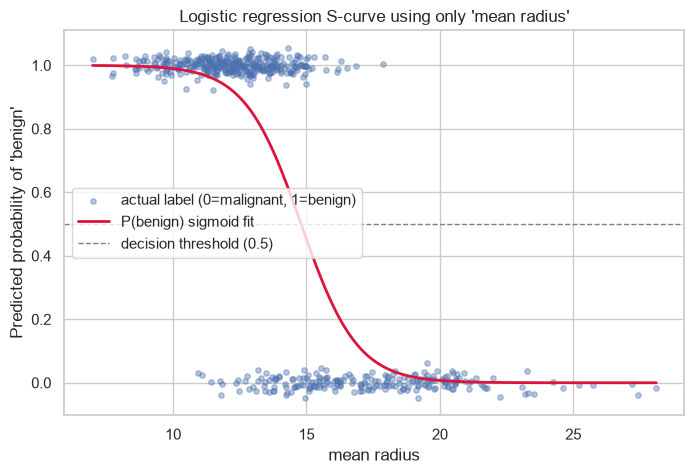

In [10]:
# Build a smooth range of x-values across the observed range of the feature
x_range = np.linspace(x_single.min(), x_single.max(), 300).reshape(-1, 1)
proba_range = single_model.predict_proba(x_range)[:, 1]

plt.figure(figsize=(8, 5))

# The raw data points, jittered slightly on the y-axis so overlapping points are visible
rng = np.random.default_rng(0)
jitter = rng.normal(0, 0.02, size=y.shape)
plt.scatter(
    x_single.ravel(), y + jitter, alpha=0.4, s=15, label="actual label (0=malignant, 1=benign)"
)

# The fitted sigmoid (S-curve)
plt.plot(x_range, proba_range, color="crimson", linewidth=2, label="P(benign) sigmoid fit")

# Decision threshold
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1, label="decision threshold (0.5)")

plt.xlabel(feature_name)
plt.ylabel("Predicted probability of 'benign'")
plt.title(f"Logistic regression S-curve using only '{feature_name}'")
plt.legend(loc="center left")
plt.show()

Notice the classic **S shape**: for small `mean radius` values the model predicts a high probability of `benign`, and as `mean radius` grows past a certain point, the predicted probability drops sharply toward `malignant`. The steepness and location of that drop are controlled by the model's learned coefficient and intercept for this feature.

## Recap

- We loaded the breast cancer dataset into a DataFrame and checked class balance (roughly 63% benign / 37% malignant).
- We trained a logistic regression model on all 30 features and evaluated it with accuracy, a confusion matrix, and an ROC/AUC curve.
- Because the full model's decision function lives in 30 dimensions, we trained a second, single-feature model on `mean radius` just to visualize the sigmoid/S-curve shape that underlies every logistic regression prediction.

Try re-running the single-predictor section with a different feature (e.g. `"worst perimeter"` or `"mean concave points"`) to see how the S-curve shape and single-feature accuracy change!